# Bài 4. Phân đoạn ảnh dựa trên vùng

**Nội dung:** (1) tự lập trình region growing, khảo sát vị trí seed và ngưỡng đồng nhất; (2) K-means (K = 2, 3, 4, 5)
và SLIC superpixels với nhiều bộ tham số; (3) thêm phương pháp **graph-based segmentation (Felzenszwalb)**, rồi so sánh
các phương pháp.

**Ảnh đầu vào:** `coins.png` (303×384, xám) cho region growing và K-means xám; `coffee.png` (ảnh màu mẫu scikit-image, thu
nhỏ còn 200×300 để chạy nhanh) cho region growing trong không gian màu, K-means, SLIC, Felzenszwalb.

In [1]:
# ===== Cài đặt & hàm tiện ích dùng chung =====
import os, time, warnings
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data, color, filters, morphology, measure, segmentation, util
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 80, "font.size": 9, "axes.titlesize": 9})

# Thư mục ảnh đầu vào / kết quả.
# Muốn dùng ảnh trong bộ dữ liệu LMS: chép ảnh vào images/ và đổi tên file ở ô "Ảnh đầu vào".
IMG_DIR, OUT_DIR = "images", "outputs/bai4"
for d in (IMG_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)


def load_rgb(name, fallback, max_side=None):
    """Đọc ảnh màu RGB từ images/<name>; nếu chưa có thì lấy ảnh mẫu rồi lưu lại."""
    p = os.path.join(IMG_DIR, name)
    if not os.path.exists(p):
        cv2.imwrite(p, cv2.cvtColor(fallback(), cv2.COLOR_RGB2BGR))
    img = cv2.cvtColor(cv2.imread(p, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    if max_side and max(img.shape[:2]) > max_side:
        s = max_side / max(img.shape[:2])
        img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    return img


def load_gray(name, fallback, max_side=None):
    """Đọc ảnh xám uint8 từ images/<name>; nếu chưa có thì lấy ảnh mẫu rồi lưu lại."""
    p = os.path.join(IMG_DIR, name)
    if not os.path.exists(p):
        cv2.imwrite(p, fallback())
    img = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    if max_side and max(img.shape) > max_side:
        s = max_side / max(img.shape)
        img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    return img


def show(images, titles=None, ncols=4, name=None, cell=3.0, cmap="gray"):
    """Hiển thị lưới ảnh; ảnh 2-D hiển thị theo thang xám cố định; lưu vào OUT_DIR/name."""
    n = len(images)
    ncols = min(ncols, n)
    nrows = int(np.ceil(n / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(cell * ncols, (cell * images[0].shape[0] / images[0].shape[1] + 0.35) * nrows), squeeze=False)
    for i, ax in enumerate(axs.ravel()):
        ax.axis("off")
        if i >= n:
            continue
        im = images[i]
        if im.ndim == 2:
            if im.dtype == np.uint8:
                ax.imshow(im, cmap=cmap, vmin=0, vmax=255)
            elif im.dtype == bool:
                ax.imshow(im, cmap=cmap, vmin=0, vmax=1)
            else:
                ax.imshow(im, cmap=cmap)
        else:
            ax.imshow(im)
        if titles is not None:
            ax.set_title(titles[i])
    fig.tight_layout()
    if name:
        fig.savefig(os.path.join(OUT_DIR, name), dpi=110, bbox_inches="tight")
    plt.show()


## 4.0 Ảnh đầu vào

coins: (303, 384) | coffee gốc: (400, 600, 3) | coffee dùng: (200, 300, 3)


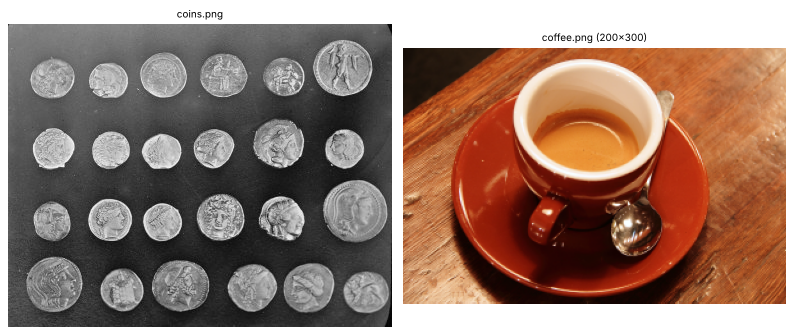

In [2]:
coins = load_gray("coins.png", data.coins)
coffee = load_rgb("coffee.png", data.coffee)
coffee_s = cv2.resize(coffee, (300, 200), interpolation=cv2.INTER_AREA)       # 200 x 300
coffee_lab = cv2.cvtColor(coffee_s, cv2.COLOR_RGB2LAB)
print("coins:", coins.shape, "| coffee gốc:", coffee.shape, "| coffee dùng:", coffee_s.shape)
show([coins, coffee_s], ["coins.png", "coffee.png (200x300)"], ncols=2, cell=5, name="b4_input.png")

## 4.1 Region growing (tự lập trình)

Thuật toán: bắt đầu từ điểm hạt (seed); duyệt BFS các láng giềng (8-liên thông); thêm điểm $q$ vào vùng nếu
$\|f(q)-\bar f_R\|\le T$ với $\bar f_R$ là **trung bình hiện thời của vùng** (`mode="mean"`) hoặc giá trị của seed
(`mode="seed"`). Chạy được cho ảnh xám (khoảng cách = |Δ|) và ảnh màu (khoảng cách Euclid trong không gian màu, ở đây CIELAB).

**Tham số:** vị trí seed, ngưỡng đồng nhất $T$, kiểu so sánh (`mean`/`seed`); ảnh được làm trơn Gaussian σ=1 trước.

seed A: tâm đồng xu lớn       = (185, 347), giá trị xám = 154
seed B: trên biên đồng xu     = (166, 338), giá trị xám = 129
seed C: nền                   = (228, 122), giá trị xám = 39
seed D: tâm đồng xu khác      = (124, 44), giá trị xám = 188


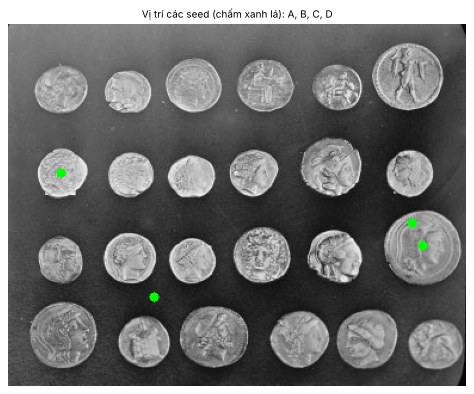

In [3]:
from collections import deque

def region_growing(img, seed, T, mode="mean", conn=8):
    """img: HxW hoặc HxWxC (float); seed=(y, x); trả về mặt nạ bool."""
    f = img.astype(np.float32)
    if f.ndim == 2:
        f = f[..., None]
    H, W, _ = f.shape
    nbrs = [(-1, 0), (1, 0), (0, -1), (0, 1)] + ([(-1, -1), (-1, 1), (1, -1), (1, 1)] if conn == 8 else [])
    mask = np.zeros((H, W), bool)
    mask[seed] = True
    total = f[seed].astype(np.float64).copy()
    n = 1
    seed_val = f[seed].copy()
    q = deque([seed])
    while q:
        y, x = q.popleft()
        for dy, dx in nbrs:
            yy, xx = y + dy, x + dx
            if 0 <= yy < H and 0 <= xx < W and not mask[yy, xx]:
                ref = total / n if mode == "mean" else seed_val
                if np.sqrt(((f[yy, xx] - ref) ** 2).sum()) <= T:
                    mask[yy, xx] = True
                    total += f[yy, xx]
                    n += 1
                    q.append((yy, xx))
    return mask

# chọn seed có ý nghĩa dựa trên ảnh nhị phân: trong đồng xu lớn, trên đường biên đồng xu, ở nền, đồng xu khác
g = cv2.GaussianBlur(coins, (0, 0), 1)
_, bw = cv2.threshold(coins, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
bw = cv2.morphologyEx(bw, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))
lab, nlab = measure.label(bw > 0, return_num=True)
props = [p for p in measure.regionprops(lab) if 800 < p.area < 5000 and p.solidity > 0.9]
big = max(props, key=lambda p: p.area)                # đồng xu lớn nhất
other = sorted(props, key=lambda p: p.area)[len(props) // 2]   # một đồng xu cỡ trung bình
cy, cx = map(int, big.centroid)
bnd = np.argwhere(segmentation.find_boundaries(lab == big.label, mode="inner"))
by, bx = bnd[len(bnd) // 4]                           # một điểm trên đường biên đồng xu
free = np.argwhere(cv2.erode(255 - bw, np.ones((9, 9), np.uint8)) > 0)
fy, fx = free[len(free) * 3 // 4]                     # một điểm nền
oy, ox = map(int, other.centroid)
seeds = {"A: tâm đồng xu lớn": (cy, cx), "B: trên biên đồng xu": (int(by), int(bx)),
         "C: nền": (int(fy), int(fx)), "D: tâm đồng xu khác": (oy, ox)}
for k, v in seeds.items():
    print(f"seed {k:24s} = {v}, giá trị xám = {int(g[v])}")

def overlay_mask(gray, mask, seed_pts=(), col=(255, 0, 0)):
    o = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)
    o[mask] = (0.45 * o[mask] + 0.55 * np.array(col)).astype(np.uint8)
    for (yy, xx) in seed_pts:
        cv2.circle(o, (int(xx), int(yy)), 4, (0, 255, 0), -1)
    return o

show([overlay_mask(coins, np.zeros_like(bw, bool), seeds.values())], ["Vị trí các seed (chấm xanh lá): A, B, C, D"], ncols=1, cell=6, name="b4_rg_seeds.png")

### (a) Khảo sát ngưỡng đồng nhất T (seed A, so với trung bình vùng)

   T  diện tích  thời gian(s)
   5         35          0.00
  10       1091          0.02
  20       2394          0.03
  40       3052          0.03


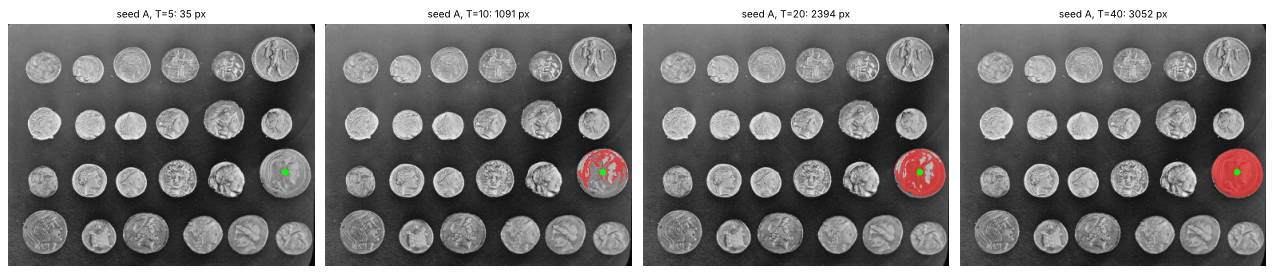

In [4]:
imgs, tits = [], []
print(f"{'T':>4s} {'diện tích':>10s} {'thời gian(s)':>13s}")
for T in (5, 10, 20, 40):
    t0 = time.perf_counter()
    m = region_growing(g, seeds["A: tâm đồng xu lớn"], T)
    dt = time.perf_counter() - t0
    imgs.append(overlay_mask(coins, m, [seeds["A: tâm đồng xu lớn"]]))
    tits.append(f"seed A, T={T}: {int(m.sum())} px")
    print(f"{T:4d} {int(m.sum()):10d} {dt:13.2f}")
show(imgs, tits, ncols=4, cell=4, name="b4_rg_thresholds.png")

### (b) Khảo sát vị trí seed (T = 15) và kiểu so sánh `mean` / `seed`

seed                       mode   diện tích
A: tâm đồng xu lớn         mean        1886
A: tâm đồng xu lớn         seed        1889
B: trên biên đồng xu       mean        1897
B: trên biên đồng xu       seed          38


C: nền                     mean       31352


C: nền                     seed       30072
D: tâm đồng xu khác        mean         935
D: tâm đồng xu khác        seed         936


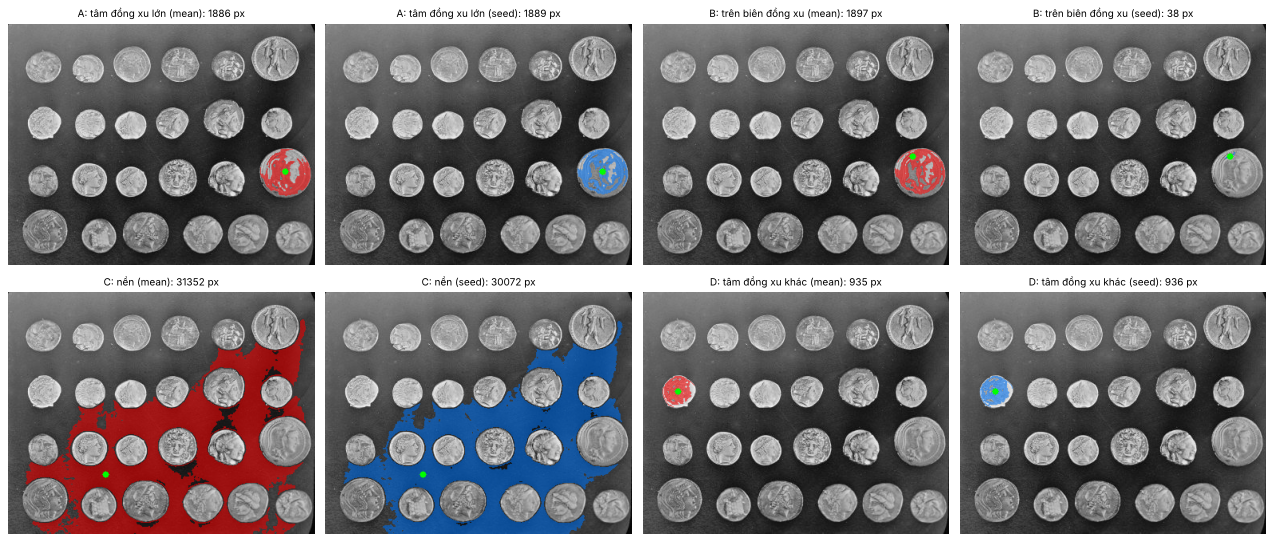

In [5]:
imgs, tits = [], []
print(f"{'seed':26s} {'mode':5s} {'diện tích':>10s}")
for name, sd in seeds.items():
    for mode in ("mean", "seed"):
        m = region_growing(g, sd, 15, mode=mode)
        print(f"{name:26s} {mode:5s} {int(m.sum()):10d}")
        if mode == "mean":
            imgs.append(overlay_mask(coins, m, [sd])); tits.append(f"{name} (mean): {int(m.sum())} px")
        else:
            imgs.append(overlay_mask(coins, m, [sd], (0, 120, 255))); tits.append(f"{name} (seed): {int(m.sum())} px")
show(imgs, tits, ncols=4, cell=4, name="b4_rg_seeds_modes.png")

### (c) Region growing trên ảnh màu (CIELAB, khoảng cách Euclid), seed trên đĩa sứ đỏ

giá trị Lab tại seed (đĩa đỏ): [ 96 178 173]


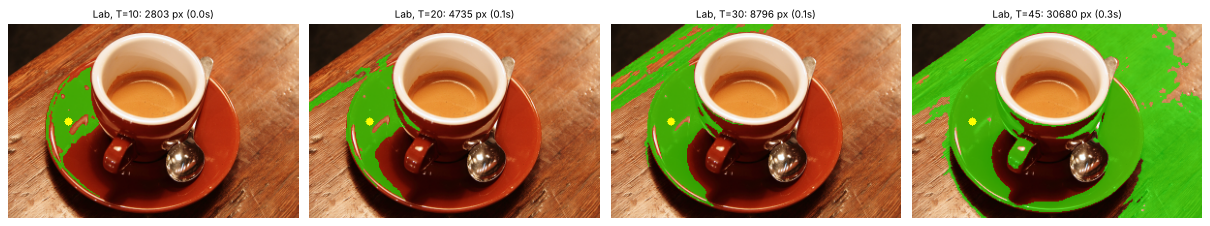

In [6]:
lab_s = cv2.GaussianBlur(coffee_lab, (0, 0), 1)
SEED_C = (100, 62)                       # (y, x) nằm trên đĩa sứ đỏ, phần được chiếu sáng
print("giá trị Lab tại seed (đĩa đỏ):", lab_s[SEED_C])
imgs, tits = [], []
for T in (10, 20, 30, 45):
    t0 = time.perf_counter()
    m = region_growing(lab_s, SEED_C, T)
    o = coffee_s.copy(); o[m] = (0.4 * o[m] + 0.6 * np.array([0, 255, 0])).astype(np.uint8)
    cv2.circle(o, (SEED_C[1], SEED_C[0]), 4, (255, 255, 0), -1)
    imgs.append(o); tits.append(f"Lab, T={T}: {int(m.sum())} px ({time.perf_counter() - t0:.1f}s)")
show(imgs, tits, ncols=4, cell=3.8, name="b4_rg_color.png")

**Nhận xét 4.1**
* **Ngưỡng T (seed A, so với trung bình vùng):** T = 5, 10, 20, 40 cho 35, 1 091, 2 394, 3 052 px. T = 5 dừng gần như ngay vì vân nổi của đồng xu khác trung bình vùng hơn 5 mức xám (*thiếu vùng*); T = 10 còn nhiều lỗ; T = 20 phủ gần hết mặt đồng xu; T = 40 phủ trọn đồng xu và dừng đúng ở biên vì nền tối (≈ 39) cách đồng xu (≈ 154) rất xa.
* **Vị trí seed (T = 15):** seed A (tâm đồng xu lớn) 1 886 px (mode `mean`) / 1 889 px (`seed`); seed D (tâm đồng xu khác) 935 / 936 px - ở vùng đồng nhất, hai kiểu so sánh gần như giống nhau. Seed B (trên biên đồng xu, mức xám 129 khác xa phần thân ≈ 154) cho kết quả rất khác nhau: `mean` cho 1 897 px (trung bình vùng trôi dần về mức xám thân đồng xu nên lan được hết đồng xu) nhưng `seed` chỉ 38 px vì mọi điểm bị so với 129. Seed C (nền) cho vùng nền liên thông rất lớn, 31 352 px (`mean`) / 30 072 px (`seed`) ≈ 27% ảnh, vì nền chiếu sáng biến thiên chậm. Vậy kết quả **phụ thuộc mạnh vào việc seed có đại diện cho vùng hay không**; `mean` linh hoạt hơn nhưng phụ thuộc thứ tự duyệt/độ trôi, `seed` ổn định nhưng nhạy với seed xấu.
* **Ảnh màu (Lab, seed trên đĩa đỏ):** T = 10, 20, 30, 45 cho 2 803, 4 735, 8 796, 30 680 px. T nhỏ chỉ lấy một phần đĩa (bóng đổ và vùng sáng phản chiếu chia cắt đĩa); T = 30 bắt đầu lấn sang vài mảng gỗ cùng tông; T = 45 **rò rỉ** ra toàn bộ mặt bàn (≈ 51% ảnh). Region growing đơn giản, kết quả liên thông và trọn vẹn, nhưng chỉ có một ngưỡng toàn cục nên nhạy với seed, thứ tự duyệt và dễ rò rỉ qua biên mờ.

## 4.2 K-means (K = 2, 3, 4, 5)

Gom cụm các pixel theo vector đặc trưng (ảnh xám: cường độ; ảnh màu: Lab) bằng `cv2.kmeans`
(`KMEANS_PP_CENTERS`, 5 lần khởi tạo, tối đa 100 vòng lặp, ε=0.2, `cv2.setRNGSeed(0)` để lặp lại được).
Tổng bình phương khoảng cách (compactness) giảm khi K tăng -> dùng đánh giá khuỷu tay (elbow).

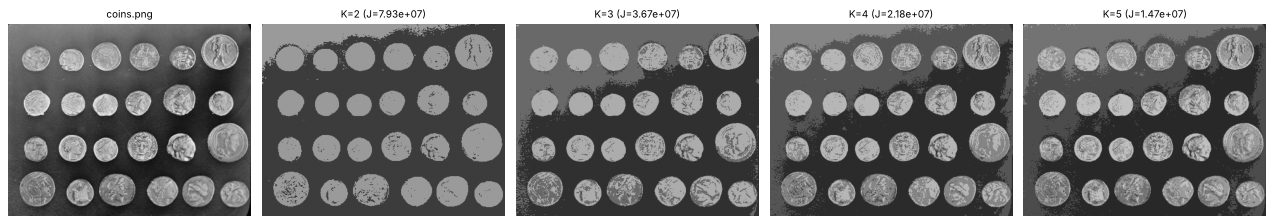

Dice(K-means K=2, Otsu) trên coins = 1.0


In [7]:
def kmeans_seg(feat, K, attempts=5):
    cv2.setRNGSeed(0)
    X = feat.reshape(-1, feat.shape[-1] if feat.ndim == 3 else 1).astype(np.float32)
    crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
    comp, labels, centers = cv2.kmeans(X, K, None, crit, attempts, cv2.KMEANS_PP_CENTERS)
    return labels.reshape(feat.shape[:2]), centers, float(comp)

# (a) ảnh xám coins
imgs, tits = [coins], ["coins.png"]
for K in (2, 3, 4, 5):
    lb, ce, comp = kmeans_seg(coins, K)
    imgs.append(ce[lb, 0].astype(np.uint8)); tits.append(f"K={K} (J={comp:.2e})")
    if K == 2:
        k2 = lb
show(imgs, tits, ncols=5, cell=3.2, name="b4_kmeans_gray.png")
# K=2 so với Otsu
hi = np.argmax(kmeans_seg(coins, 2)[1].ravel())
mk = (k2 == hi)
mo = cv2.threshold(coins, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1] > 0
print("Dice(K-means K=2, Otsu) trên coins =", round(2 * (mk & mo).sum() / (mk.sum() + mo.sum()), 4))

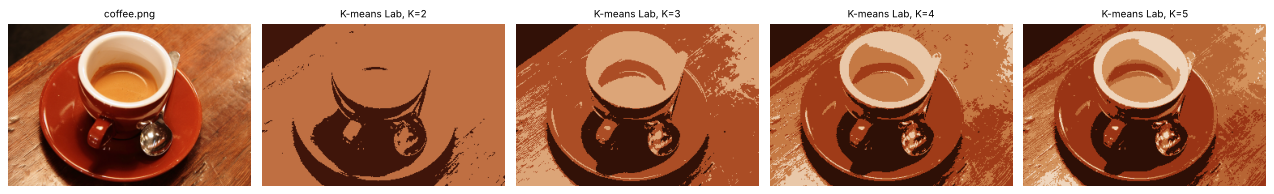

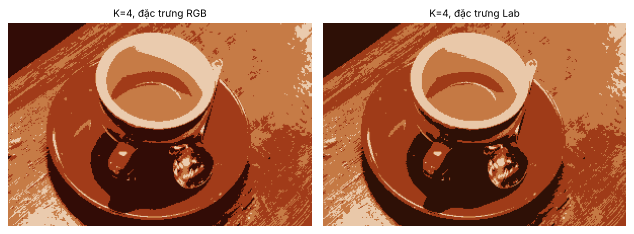

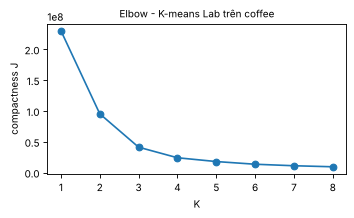

J theo K: {1: '2.302e+08', 2: '9.542e+07', 3: '4.127e+07', 4: '2.412e+07', 5: '1.796e+07', 6: '1.361e+07', 7: '1.115e+07', 8: '9.481e+06'}
K=2: 125 thành phần liên thông cho 2 cụm
K=3: 358 thành phần liên thông cho 3 cụm
K=4: 747 thành phần liên thông cho 4 cụm
K=5: 1068 thành phần liên thông cho 5 cụm


In [8]:
# (b) ảnh màu coffee, không gian Lab
imgs, tits, J = [coffee_s], ["coffee.png"], {}
for K in (2, 3, 4, 5):
    lb, ce, comp = kmeans_seg(coffee_lab, K)
    rgb_c = cv2.cvtColor(ce.astype(np.uint8).reshape(1, K, 3), cv2.COLOR_LAB2RGB).reshape(K, 3)
    imgs.append(rgb_c[lb]); tits.append(f"K-means Lab, K={K}")
    J[K] = comp
show(imgs, tits, ncols=5, cell=3.2, name="b4_kmeans_color.png")

# (c) so sánh không gian đặc trưng RGB / Lab với K=4 và đường elbow
imgs, tits = [], []
lb_rgb, ce_rgb, _ = kmeans_seg(coffee_s, 4)
imgs.append(ce_rgb.astype(np.uint8)[lb_rgb]); tits.append("K=4, đặc trưng RGB")
lb_lab, ce_lab, _ = kmeans_seg(coffee_lab, 4)
imgs.append(cv2.cvtColor(ce_lab.astype(np.uint8).reshape(1, 4, 3), cv2.COLOR_LAB2RGB).reshape(4, 3)[lb_lab]); tits.append("K=4, đặc trưng Lab")
show(imgs, tits, ncols=2, cell=4, name="b4_kmeans_rgb_lab.png")
Ks = list(range(1, 9))
Js = [kmeans_seg(coffee_lab, K)[2] for K in Ks]
fig, ax = plt.subplots(figsize=(4.5, 2.8))
ax.plot(Ks, Js, "o-"); ax.set_xlabel("K"); ax.set_ylabel("compactness J"); ax.set_title("Elbow - K-means Lab trên coffee")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "b4_kmeans_elbow.png"), dpi=110, bbox_inches="tight"); plt.show()
print("J theo K:", {K: f"{j:.3e}" for K, j in zip(Ks, Js)})
# số thành phần liên thông của từng nhãn: K-means không dùng thông tin vị trí nên vùng bị phân mảnh
for K in (2, 3, 4, 5):
    lb = kmeans_seg(coffee_lab, K)[0]
    ncc = sum(cv2.connectedComponents((lb == k).astype(np.uint8), connectivity=8)[0] - 1 for k in range(K))
    print(f"K={K}: {ncc} thành phần liên thông cho {K} cụm")

**Nhận xét 4.2**
* **Ảnh xám (`coins.png`):** K = 2 trùng **hoàn toàn** với Otsu (Dice = 1,0) vì Otsu thực chất là K-means 2 cụm một chiều (cùng cực tiểu phương sai trong lớp). K = 3, 4, 5 chia thêm các mức xám của vân đồng xu và độ chuyển sáng của nền.
* **Ảnh màu (Lab, `coffee.png`):** K = 2 chỉ tách sáng/tối (bóng đổ riêng một cụm); K = 3 tách thêm vành/lòng cốc sáng; K = 4 tách được bóng tối, đĩa đỏ, gỗ (gộp cả cà phê vì cùng tông), vành cốc trắng; K = 5 tách thêm vùng cà phê trong cốc. Compactness J giảm mạnh đến K = 4 (2,30·10⁸ -> 9,54·10⁷ -> 4,13·10⁷ -> 2,41·10⁷) rồi chậm lại (1,80·10⁷ ở K = 5, 1,36·10⁷ ở K = 6) - khuỷu quanh K = 4 - 5. Đặc trưng RGB và Lab cho K = 4 gần như giống nhau trên ảnh này.
* **Hạn chế:** K-means không dùng vị trí nên một cụm bị chia thành rất nhiều mảnh rời: K = 2, 3, 4, 5 cho 125, 358, 747, 1 068 thành phần liên thông; cùng màu thì gộp dù là hai vật khác nhau (bóng đổ trên bàn và bóng dưới đĩa, thìa kim loại cùng cụm tối). Phải chọn K trước.

## 4.3 SLIC superpixels

`skimage.segmentation.slic`: K-means cục bộ trong không gian 5-D (Lab + vị trí). **Tham số:** `n_segments` ∈ {50, 200, 800},
`compactness` ∈ {1, 10, 40} (lớn -> superpixel vuông vức, đều; nhỏ -> bám biên màu), `sigma` làm trơn.

 n_segments  compactness  số SP thực  thời gian(s)


         50            1          27         0.088
         50           10          44         0.056


         50           40          54         0.056
        200            1         112         0.070


        200           10         178         0.070


        200           40         216         0.068
        800            1         432         0.079


        800           10         652         0.073


        800           40         718         0.072


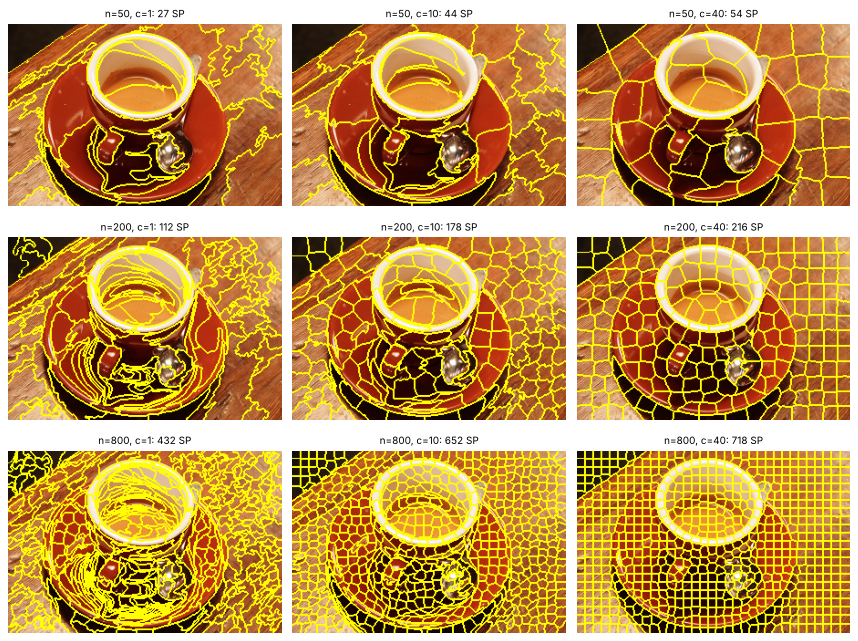

In [9]:
imgs, tits = [], []
slic_info = {}
print(f"{'n_segments':>11s} {'compactness':>12s} {'số SP thực':>11s} {'thời gian(s)':>13s}")
for ns in (50, 200, 800):
    for cp in (1, 10, 40):
        t0 = time.perf_counter()
        sp = segmentation.slic(coffee_s, n_segments=ns, compactness=cp, sigma=1, start_label=0)
        dt = time.perf_counter() - t0
        slic_info[(ns, cp)] = sp
        print(f"{ns:11d} {cp:12d} {sp.max() + 1:11d} {dt:13.3f}")
        imgs.append(segmentation.mark_boundaries(coffee_s, sp, color=(1, 1, 0)))
        tits.append(f"n={ns}, c={cp}: {sp.max() + 1} SP")
show(imgs, tits, ncols=3, cell=3.6, name="b4_slic_grid.png")

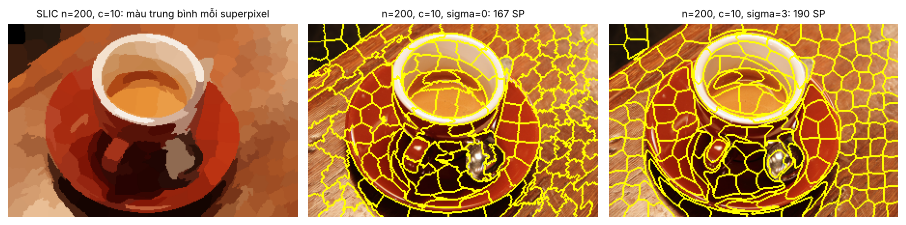

In [10]:
# hiển thị superpixel dưới dạng màu trung bình + ảnh hưởng của sigma (n=200, c=10)
sp = slic_info[(200, 10)]
avg = color.label2rgb(sp, coffee_s, kind="avg")
imgs, tits = [avg], ["SLIC n=200, c=10: màu trung bình mỗi superpixel"]
for sg in (0, 3):
    s2 = segmentation.slic(coffee_s, n_segments=200, compactness=10, sigma=sg, start_label=0)
    imgs.append(segmentation.mark_boundaries(coffee_s, s2, color=(1, 1, 0))); tits.append(f"n=200, c=10, sigma={sg}: {s2.max() + 1} SP")
show(imgs, tits, ncols=3, cell=3.8, name="b4_slic_avg_sigma.png")

**Nhận xét 4.3**
* `n_segments` = 50, 200, 800 với `compactness` = 1 / 10 / 40 cho số superpixel thực 27 / 44 / 54, 112 / 178 / 216 và 432 / 652 / 718: compactness nhỏ làm số vùng thực thấp hơn nhiều so với yêu cầu (các mảnh nhỏ bị gộp để đảm bảo liên thông), compactness lớn thì gần đúng yêu cầu. Thời gian chỉ ≈ 0,06 - 0,09 s, gần như không đổi.
* `compactness` = 1: superpixel bám biên màu tốt (đường viền cốc, bóng đổ) nhưng hình dạng méo, kích thước không đều; = 40: gần như lưới đều, ít bám biên, cắt ngang vành cốc; = 10 là cân bằng tốt (vừa đều, vừa theo biên). `n_segments` tăng thì biên chính xác hơn nhưng vùng nhỏ hơn.
* `sigma` = 0, 1, 3 (n = 200, c = 10) cho 167, 178, 190 superpixel: làm trơn mạnh hơn loại bỏ kết cấu hạt của vân gỗ nên vùng đều đặn hơn và số vùng gần giá trị yêu cầu. Ảnh "màu trung bình" cho thấy superpixel giữ được hình cốc/đĩa với chỉ ~180 vùng -> dùng làm tầng tiền xử lý rất tốt.

## 4.4 Phương pháp bổ sung: graph-based segmentation (Felzenszwalb-Huttenlocher)

Ảnh là đồ thị lưới, cạnh có trọng số = độ khác biệt màu; gộp hai thành phần nếu cạnh nhỏ nhất nối chúng nhẹ hơn
ngưỡng nội tại (phụ thuộc `scale`/kích thước thành phần). **Tham số:** `scale` ∈ {50, 200, 800}, `sigma` ∈ {0.5, 1.5},
`min_size` = 50.

 scale  sigma  số vùng  thời gian(s)
    50    0.5      167         0.066
   200    0.5       74         0.066


   800    0.5       29         0.071
    50    1.5      142         0.085
   200    1.5       39         0.074


   800    1.5       13         0.078


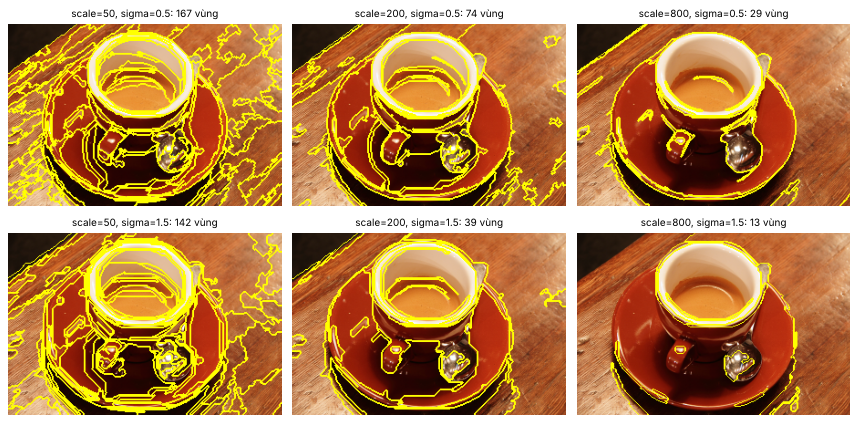

In [11]:
imgs, tits = [], []
felz = {}
print(f"{'scale':>6s} {'sigma':>6s} {'số vùng':>8s} {'thời gian(s)':>13s}")
for sg in (0.5, 1.5):
    for sc in (50, 200, 800):
        t0 = time.perf_counter()
        fl = segmentation.felzenszwalb(coffee_s, scale=sc, sigma=sg, min_size=50)
        dt = time.perf_counter() - t0
        felz[(sc, sg)] = fl
        print(f"{sc:6d} {sg:6.1f} {fl.max() + 1:8d} {dt:13.3f}")
        imgs.append(segmentation.mark_boundaries(coffee_s, fl, color=(1, 1, 0)))
        tits.append(f"scale={sc}, sigma={sg}: {fl.max() + 1} vùng")
show(imgs, tits, ncols=3, cell=3.6, name="b4_felz_grid.png")

## 4.5 So sánh các phương pháp trên cùng ảnh `coffee.png`

Không có ground-truth nên dùng các số đo nội tại: **số vùng**, **số thành phần liên thông** (vùng rời rạc),
**độ đồng nhất** = độ lệch Euclid trung bình trong Lab của pixel so với màu trung bình vùng của nó (thấp = đồng nhất hơn),
và thời gian chạy. Lưu ý độ đồng nhất tất nhiên giảm khi số vùng tăng -> chỉ so sánh công bằng giữa các phương pháp có số vùng gần nhau.

phương pháp                       số nhãn  số TP liên thông  độ đồng nhất ↓  thời gian(s)
K-means K=4 (Lab)                       4               747           17.94         0.048
K-means K=8 (Lab)                       8              1860           11.07         0.113
SLIC n=50, c=10                        44                44           16.15         0.060
SLIC n=200, c=10                      178               178           13.47         0.071
Felzenszwalb scale=800                 29                29           36.39         0.067


Felzenszwalb scale=200                 74                74           17.83         0.067


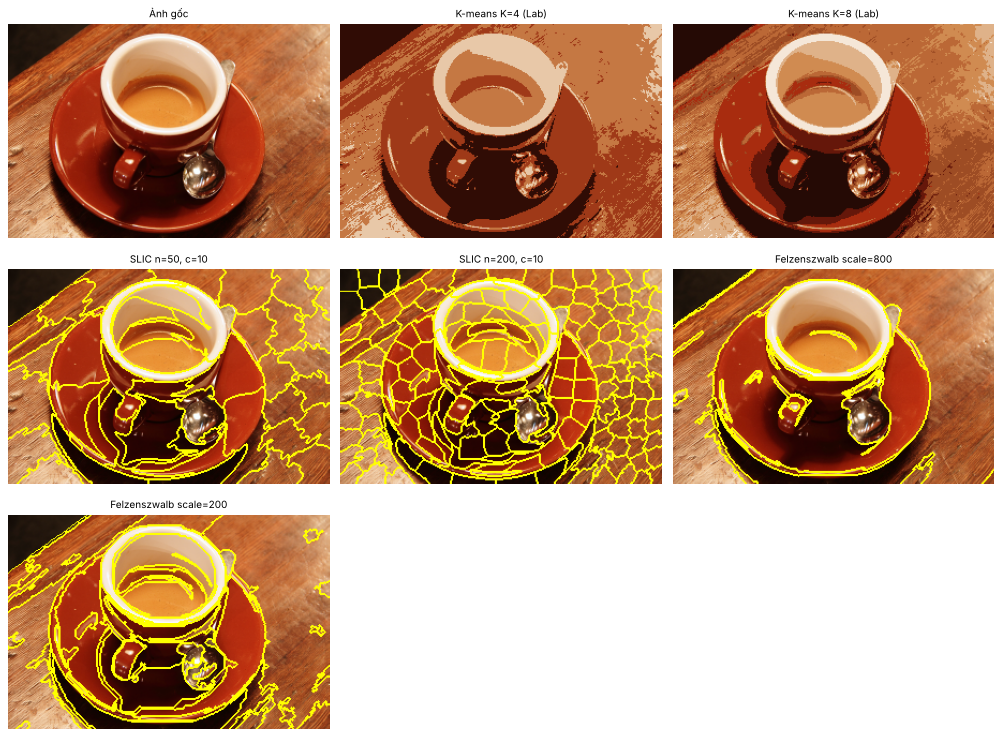

In [12]:
def homogeneity(labels, lab_img):
    lab_f = lab_img.astype(np.float32)
    err = np.zeros(labels.shape, np.float32)
    for k in np.unique(labels):
        m = labels == k
        err[m] = np.sqrt(((lab_f[m] - lab_f[m].mean(0)) ** 2).sum(1))
    return float(err.mean())

def n_regions_connected(labels):
    return sum(cv2.connectedComponents((labels == k).astype(np.uint8), connectivity=8)[0] - 1 for k in np.unique(labels))

cands = {}
t0 = time.perf_counter(); lb4 = kmeans_seg(coffee_lab, 4)[0]; cands["K-means K=4 (Lab)"] = (lb4, time.perf_counter() - t0)
t0 = time.perf_counter(); lb8 = kmeans_seg(coffee_lab, 8)[0]; cands["K-means K=8 (Lab)"] = (lb8, time.perf_counter() - t0)
t0 = time.perf_counter(); s1 = segmentation.slic(coffee_s, n_segments=50, compactness=10, sigma=1, start_label=0); cands["SLIC n=50, c=10"] = (s1, time.perf_counter() - t0)
t0 = time.perf_counter(); s2 = segmentation.slic(coffee_s, n_segments=200, compactness=10, sigma=1, start_label=0); cands["SLIC n=200, c=10"] = (s2, time.perf_counter() - t0)
t0 = time.perf_counter(); f1 = segmentation.felzenszwalb(coffee_s, scale=800, sigma=0.5, min_size=50); cands["Felzenszwalb scale=800"] = (f1, time.perf_counter() - t0)
t0 = time.perf_counter(); f2 = segmentation.felzenszwalb(coffee_s, scale=200, sigma=0.5, min_size=50); cands["Felzenszwalb scale=200"] = (f2, time.perf_counter() - t0)

print(f"{'phương pháp':32s} {'số nhãn':>8s} {'số TP liên thông':>17s} {'độ đồng nhất ↓':>15s} {'thời gian(s)':>13s}")
imgs, tits = [coffee_s], ["Ảnh gốc"]
for name, (lb, dt) in cands.items():
    print(f"{name:32s} {len(np.unique(lb)):8d} {n_regions_connected(lb):17d} {homogeneity(lb, coffee_lab):15.2f} {dt:13.3f}")
    if "K-means" in name:
        cl = np.array([coffee_s[lb == k].mean(0) for k in range(lb.max() + 1)]).astype(np.uint8)
        imgs.append(cl[lb])
    else:
        imgs.append(segmentation.mark_boundaries(coffee_s, lb, color=(1, 1, 0)))
    tits.append(name)
show(imgs, tits, ncols=3, cell=4.2, name="b4_compare.png")

**Nhận xét 4.4 - 4.5**
* **Felzenszwalb (graph-based):** `scale` điều khiển cỡ vùng: scale = 50, 200, 800 (σ = 0,5) cho 167, 74, 29 vùng; σ = 1,5 cho 142, 39, 13 vùng. Biên của vùng bám theo vật thể (đường viền cốc, đĩa, thìa) và kích thước vùng **không đều**: vùng phẳng (bàn gỗ, mặt đĩa) lớn, vùng nhiều chi tiết (thìa) nhỏ. scale = 800 gần với phân đoạn theo vật thể nhất (cốc - đĩa - bàn) dù độ đồng nhất số học kém nhất.
* **So sánh (độ đồng nhất ↓ tốt hơn, đo bằng khoảng cách Lab TB tới màu trung bình vùng):** K-means K = 4: 17,94 (4 nhãn nhưng 747 mảnh rời); K = 8: 11,07 (1 860 mảnh); SLIC 44 vùng: 16,15; SLIC 178 vùng: 13,47; Felzenszwalb 74 vùng: 17,83; Felzenszwalb 29 vùng: 36,39. Ở số vùng tương đương (khoảng 40 - 75), SLIC (16,15) đồng nhất hơn Felzenszwalb (17,83) vì ép các vùng kích thước đều; K-means đồng nhất rất tốt ngay với K nhỏ nhưng phải trả giá bằng hàng trăm mảnh không liên thông. Cả ba chạy rất nhanh (≈ 0,05 - 0,14 s trên ảnh 200×300). Số đo này là nội tại, chỉ đánh giá màu đồng đều chứ không phải độ đúng theo ngữ nghĩa.
* **Chọn phương pháp:** K-means - phân lớp theo màu toàn cục, không cần vị trí, nhưng vùng phân mảnh; SLIC - tiền xử lý/superpixel đều, nhanh, ổn định nhưng không theo vật thể; Felzenszwalb - vùng thích nghi theo nội dung, gần vật thể hơn nhưng khó kiểm soát số vùng; Region growing - chỉ lấy một vật quanh seed, kết quả liên thông nhưng cần chọn seed và T cẩn thận (đã thấy rò rỉ ở T = 45). Region growing không đưa vào bảng so sánh vì chỉ phân đoạn một đối tượng.